In [1]:
!pip install pillow-heif
!pip install -U albumentations
!pip install torch_optimizer
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 45.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.4/369.4 kB 8.5 MB/s eta 0:00:00
  Attempting uninstall: albucore
    Found existing installation: albucore 0.0.23
    Uninstalling albucore-0.0.23:
      Successfully uninstalled albucore-0.0.23
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.5
    Uninstalling albumentations-2.0.5:
      Successfully uninstalled albumentations-2.0.5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.9/55.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.9/61.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt
import numpy as np
import gc
import os
from PIL import Image
import torch.optim as optim
import albumentations as A
from albumentations.pytorch import ToTensorV2


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gc.collect()
torch.cuda.empty_cache()

In [3]:
import os
from PIL import Image
import pillow_heif
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Register HEIC support
pillow_heif.register_heif_opener()

class CustomImageDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        self.image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.heic'))]

    def __len__(self):
        return len(self.image_files)
    def __getitem__(self, idx):
        path = os.path.join(self.image_dir, self.image_files[idx])
        img  = Image.open(path).convert('RGB')

        if self.transform:
            img_np    = np.array(img)                     # PIL→H×W×C NumPy
            augmented = self.transform(image=img_np)      # <-- pass as keyword
            img_tensor = augmented['image']               # torch.Tensor from ToTensorV2
            return img_tensor, 0

        # if no transform, fallback to pure PIL→Tensor
        return transforms.ToTensor()(img), 0


def keep_first_channel(img, **kwargs):
    return img[..., :1]


PATCH_SIZE = 128
albumentations_transform = A.Compose([
    # 1) Resize whole image to 1400×1400
    A.Resize(height=256, width=300),

    # 2) Center‐crop to 512×512
    A.CenterCrop(height=PATCH_SIZE, width=PATCH_SIZE),

    # 3) Drop into random patch of exactly PATCH_SIZE (optional if you want random crops instead of center)
    # A.RandomCrop(height=PATCH_SIZE, width=PATCH_SIZE),

    # 4) Convert to single‐channel (grayscale)
    A.ToGray(p=1.0),
    # drop the extra 2 channels
    A.Lambda(image=keep_first_channel),

    # 5) Geometric / photometric augmentations
    A.HorizontalFlip(p=0.5),
    # A.VerticalFlip(p=0.5),
    # A.RandomRotate90(p=0.5),
    # A.Transpose(p=0.5),
    A.Affine(scale=(0.96,1.04), translate_percent=0.01, rotate=0, p=0.25),

    A.RandomBrightnessContrast(p=0.5),
    A.RandomGamma(p=0.25),
    A.Emboss(p=0.25),
    A.Blur(blur_limit=3, p=0.01),

    A.OneOf([
        A.ElasticTransform(alpha=120, sigma=6, p=1.0),
        # A.GridDistortion(p=1.0),
        A.OpticalDistortion(distort_limit=2.0, p=1.0),
    ], p=0.3),

    # 6) Normalize to mean=0.5, std=0.5 in [0,1] intensity range
    A.Normalize(mean=(0.5,), std=(0.5,)),

    # 7) Convert H×W×C NumPy → torch.Tensor (C×H×W)
    ToTensorV2(),
])




# Process HEIC images to JPEG if needed
def process_images(data_path, new_data_path):
    if not os.path.exists(new_data_path):
        os.makedirs(new_data_path)
    for file in os.listdir(data_path):
        if file.lower().endswith('.heic'):
            img_path = os.path.join(data_path, file)
            img = Image.open(img_path).convert('RGB')
            base, _ = os.path.splitext(file)
            save_path = os.path.join(new_data_path, base + '.jpg')
            img.save(save_path, format='JPEG')
        elif file.lower().endswith(('.jpg', '.jpeg', '.png')):
            src = os.path.join(data_path, file)
            dst = os.path.join(new_data_path, file)
            if not os.path.exists(dst):
                os.link(src, dst)  # or use shutil.copy(src, dst)

In [ ]:
data_path = "../data/images_dataset/"
new_data_path = "/kaggle/input/dataset/processed_images/"

In [5]:
# process_images(data_path, new_data_path)

In [6]:
dataset = CustomImageDataset(new_data_path, transform=albumentations_transform)

Batch 1 - Image shape: torch.Size([16, 1, 128, 128])


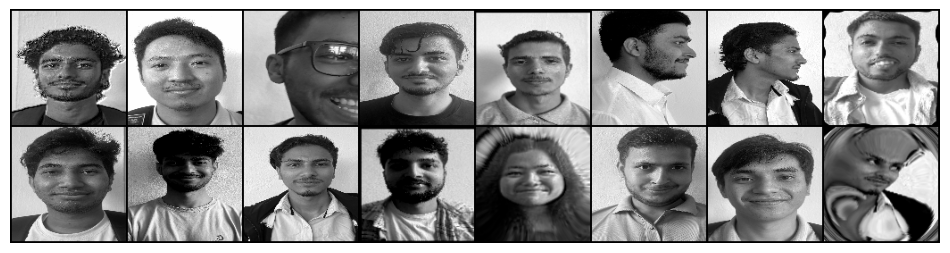

Batch 2 - Image shape: torch.Size([16, 1, 128, 128])


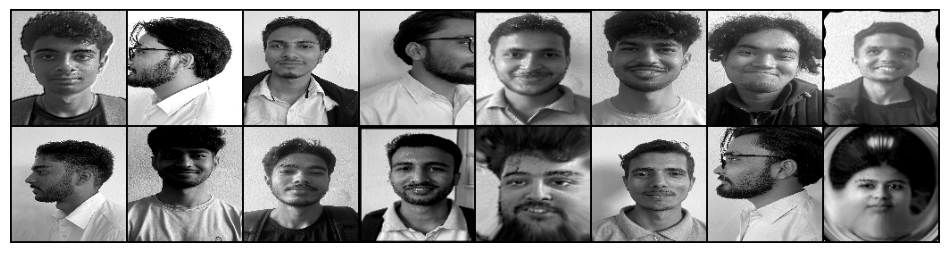

Batch 3 - Image shape: torch.Size([16, 1, 128, 128])


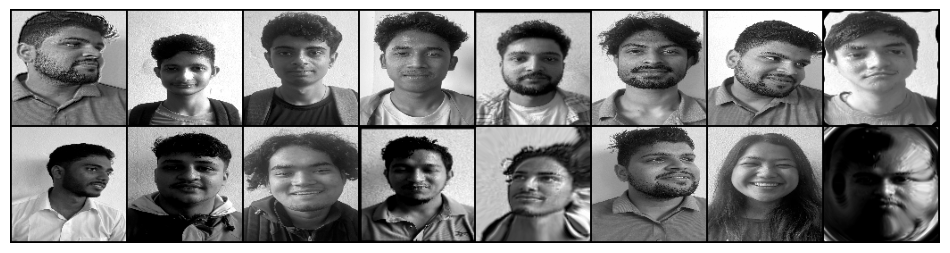

Batch 4 - Image shape: torch.Size([16, 1, 128, 128])


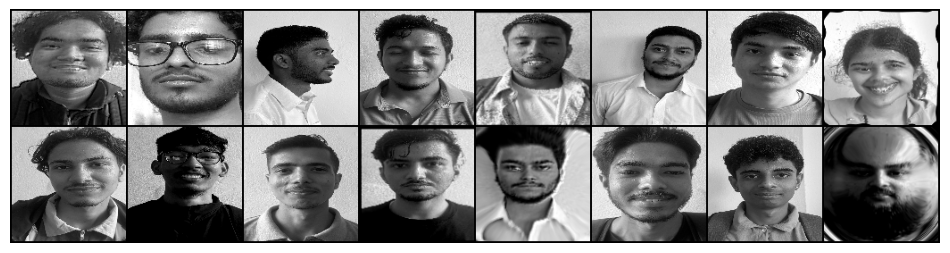

Batch 5 - Image shape: torch.Size([16, 1, 128, 128])


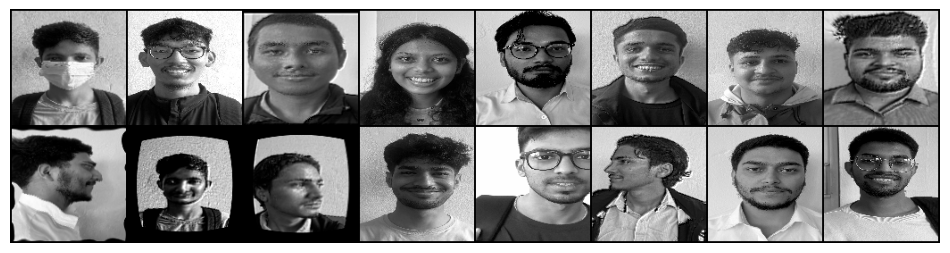

Batch 6 - Image shape: torch.Size([6, 1, 128, 128])


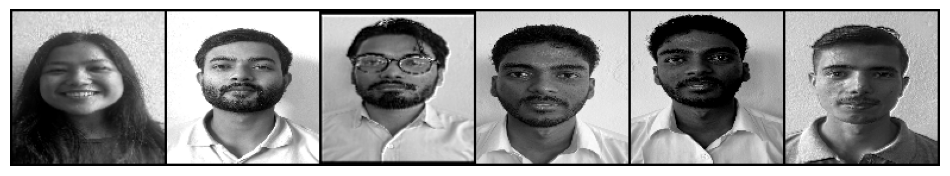

In [7]:
train_loader = DataLoader(dataset, batch_size=16, shuffle=True, num_workers=4)

for i, (images, _) in enumerate(train_loader):
    images = images.to(device)
    print(f"Batch {i+1} - Image shape: {images.shape}")
    # Display the images
    grid = make_grid(images, nrow=8, normalize=True, scale_each=True)
    plt.figure(figsize=(12, 12))
    plt.imshow(grid.cpu().numpy().transpose((1, 2, 0)), cmap='gray')
    plt.axis('off')
    plt.show()
    
    if i == 5:  # Display only the first 6 batches
        break

In [8]:
def show_images(images, nrow=8, title=None):
    grid = make_grid(images, nrow=nrow)
    plt.figure(figsize=(10, 10))
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    plt.axis('off')
    if title:
        plt.title(title)
    plt.show()  
def save_images(images, filename):
    grid = make_grid(images, nrow=8, normalize=True, scale_each=True)
    save_image(grid, filename)
    print(f"Images saved to {filename}")

def plot_images_from_loader(loader, num_images=64, save=False):
    images = []
    for i, (img_batch, _) in enumerate(loader):
        if i * loader.batch_size >= num_images:
            break
        images.append(img_batch)
    
    images = torch.cat(images, dim=0)[:num_images]
    
    if save:
        save_images(images, "sample_images.png")
    else:
        show_images(images, nrow=8)

plot_images_from_loader(train_loader, num_images=64, save=True)

Images saved to sample_images.png


In [ ]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super(Generator, self).__init__()
        self.noise_dim = noise_dim
        
        self.fc = nn.Sequential(
            nn.Linear(noise_dim, 256 * 8 * 8),
            nn.BatchNorm1d(256 * 8 * 8),
            nn.ReLU(True)
        )
        
        self.up_blocks = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 16x16
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 32x32
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 64x64
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),  
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 128x128
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.fc(x)
        x = x.view(-1, 256, 8, 8)
        x = self.up_blocks(x)
        return x


In [11]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),   # 64x64
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),  # 32x32
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 16x16
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 8x8
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), # 4x4
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


In [13]:
# Using available hardware device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Creating the generator and discriminator
latent_dim = 100
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)

# creating binary cross entropy loss instancea
criterion = nn.BCELoss()


In [ ]:
import optuna
from torch.utils.data import DataLoader
import torch.nn as nn
import torch
from torch_optimizer import RAdam, Lookahead

def objective(trial):
    # Sample hyperparameters
    lr = trial.suggest_float("lr", 1e-5, 5e-4, log=True)
    batch_size = trial.suggest_categorical("batch_size", [8, 16])
    optimizer_name = trial.suggest_categorical("optimizer", ["adam", "radam", "lookahead-radam"])
    
    # Dataloader
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    
    # Model & Criterion
    G = Generator().to(device)
    D = Discriminator().to(device)
    criterion = nn.BCELoss()
    
    # Optimizers
    if optimizer_name == "adam":
        g_optim = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
        d_optim = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    elif optimizer_name == "radam":
        g_optim = RAdam(G.parameters(), lr=lr, betas=(0.5, 0.999))
        d_optim = RAdam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    elif optimizer_name == "lookahead-radam":
        g_optim = Lookahead(RAdam(G.parameters(), lr=lr, betas=(0.5, 0.999)))
        d_optim = Lookahead(RAdam(D.parameters(), lr=lr, betas=(0.5, 0.999)))
    
    latent_dim = 100
    num_epochs = 10
    g_total_loss = 0.0
    
    for epoch in range(num_epochs):
        for real_images, _ in loader:
            real_images = real_images.to(device)
            batch_size = real_images.size(0)

            real_labels = torch.full((batch_size, 1), 0.9, device=device)
            fake_labels = torch.full((batch_size, 1), 0.1, device=device)

            ### Train D
            d_optim.zero_grad()
            real_out = D(real_images)
            d_real_loss = criterion(real_out, real_labels)

            z = torch.randn(batch_size, latent_dim).to(device)
            fake_imgs = G(z)
            fake_out = D(fake_imgs.detach())
            d_fake_loss = criterion(fake_out, fake_labels)

            d_loss = d_real_loss + d_fake_loss
            d_loss.backward()
            d_optim.step()

            ### Train G
            g_optim.zero_grad()
            g_loss = criterion(D(fake_imgs), real_labels)
            g_total_loss += g_loss.item()
            g_loss.backward()
            g_optim.step()
    
    avg_g_loss = g_total_loss / (num_epochs * len(loader))
    trial.report(avg_g_loss, epoch)

    if trial.should_prune():
        raise optuna.TrialPruned()
    return avg_g_loss  


In [ ]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)  
best_params = study.best_params
print(f"Retraining with best params: {best_params}")

[I 2025-07-08 12:14:40,639] A new study created in memory with name: no-name-2b7b3efc-f5cd-4452-80f3-a6570f3a4cb8
[I 2025-07-08 12:17:18,549] Trial 0 finished with value: 0.750547669692473 and parameters: {'lr': 0.00011582825233719987, 'batch_size': 8, 'optimizer': 'adam'}. Best is trial 0 with value: 0.750547669692473.
[I 2025-07-08 12:19:52,874] Trial 1 finished with value: 0.7911356351592324 and parameters: {'lr': 0.00017706144243220806, 'batch_size': 8, 'optimizer': 'adam'}. Best is trial 0 with value: 0.750547669692473.
[I 2025-07-08 12:22:28,798] Trial 2 finished with value: 0.7517102620818398 and parameters: {'lr': 0.00013203772618983642, 'batch_size': 8, 'optimizer': 'adam'}. Best is trial 0 with value: 0.750547669692473.
[I 2025-07-08 12:25:03,610] Trial 3 finished with value: 0.6916434407234192 and parameters: {'lr': 2.1876622548214997e-05, 'batch_size': 8, 'optimizer': 'lookahead-radam'}. Best is trial 3 with value: 0.6916434407234192.
[I 2025-07-08 12:27:47,916] Trial 4 fin

Retraining with best params: {'lr': 0.00017558485508404896, 'batch_size': 16, 'optimizer': 'lookahead-radam'}


In [16]:
print(f"Loss: {study.best_value}")
print(f"Params: {study.best_params}")

Loss: 0.684782475233078
Params: {'lr': 0.00017558485508404896, 'batch_size': 16, 'optimizer': 'lookahead-radam'}


In [17]:
import joblib
joblib.dump(study, "gan_tuning_study.pkl")

['gan_tuning_study.pkl']